# Online Purchase Order Risk Prediction

A machine learning project for identifying high-risk online purchase orders using cost-sensitive classification.

### Objective
The goal of this project is to predict whether an online purchase order is high risk or low risk.

- `CLASS = yes`: High Risk
- `CLASS = no`: Low Risk

The project uses machine learning and deep learning classification methods and evaluates them using both predictive performance and misclassification cost.

## 1. Dataset Files

Two text files are provided:

- `risk-dataset.txt`: contains the online purchase order records used for model training and testing.
- `risk-attributes.txt`: describes the meaning of each dataset attribute.

The dataset contains 30,000 purchase orders and 44 attributes.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Attribute Description

The attribute file is used as documentation to understand the meaning of the variables before preprocessing.

In [2]:
with open("risk-attributes.txt", "r", encoding="utf-8") as file:
    attribute_lines = file.readlines()

print("".join(attribute_lines[:20]))

Description of the attributes

Name of Attribute     Description
ORDER_ID              ID number of the online order
CLASS                 Class attribute of the task (yes/no)
                      (only contained in the training data)
B_EMAIL               was an email address submitted together with the order (yes/no)
B_TELEFON             was an phone number submitted together with the order (yes/no)
B_BIRTHDATE           Birth date, if submitted together with the order
FLAG_LRIDENTISCH      if address of delievery and invoice are identical then "yes" else "no"
FLAG_NEWSLETTER       was the E-Newsletter subscribed to together with the order (yes/no)
Z_METHODE             Selected method of payment
Z_CARD_ART            Selected type of card if payment by card is chosen
Z_CARD_VALID          Expiration date of the card in the form month.year
                      (e.g. 05.2006 meaning the card is valide till May 2006)
Z_LAST_NAME           is the name of the account or card holder id

## 3. Load the Dataset

The dataset is tab-separated. Missing values represented by `?` are converted to `NaN`.

In [3]:
df = pd.read_csv(
    "risk-dataset.txt",
    sep="\t",
    na_values="?",
    dtype={"Z_CARD_VALID": "string"}
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (30000, 44)


,ORDER_ID,CLASS,B_EMAIL,B_TELEFON,B_BIRTHDATE,FLAG_LRIDENTISCH,FLAG_NEWSLETTER,Z_METHODE,Z_CARD_ART,Z_CARD_VALID,...,FAIL_RPLZ,FAIL_RORT,FAIL_RPLZORTMATCH,SESSION_TIME,NEUKUNDE,AMOUNT_ORDER_PRE,VALUE_ORDER_PRE,DATE_LORDER,MAHN_AKT,MAHN_HOECHST
0,49917,no,yes,no,1/17/1973,yes,yes,check,NaN,5.2006,...,no,no,no,8,yes,0,0.00,NaN,NaN,NaN
1,49919,no,yes,yes,12/8/1970,no,no,credit_card,Visa,12.2007,...,yes,no,no,13,yes,0,0.00,NaN,NaN,NaN
2,49923,no,yes,no,4/3/1972,yes,no,check,NaN,12.2007,...,no,no,no,3,yes,0,0.00,NaN,NaN,NaN
3,49924,no,no,yes,8/1/1966,yes,no,check,NaN,1.2007,...,no,no,no,11,no,4,75.72,5/12/2002,0.0,0.0
4,49927,no,yes,yes,12/21/1969,yes,no,credit_card,Eurocard,12.2006,...,no,no,no,16,yes,0,0.00,NaN,NaN,NaN


## 4. Initial Data Exploration

The dataset is examined for:

- dataset dimensions
- target class distribution
- data types
- missing values

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nTarget Distribution:")
print(df["CLASS"].value_counts())

print("\nTarget Percentage:")
print(df["CLASS"].value_counts(normalize=True) * 100)

Rows: 30000
Columns: 44

Target Distribution:
CLASS
no     28254
yes     1746
Name: count, dtype: int64

Target Percentage:
CLASS
no     94.18
yes     5.82
Name: proportion, dtype: float64


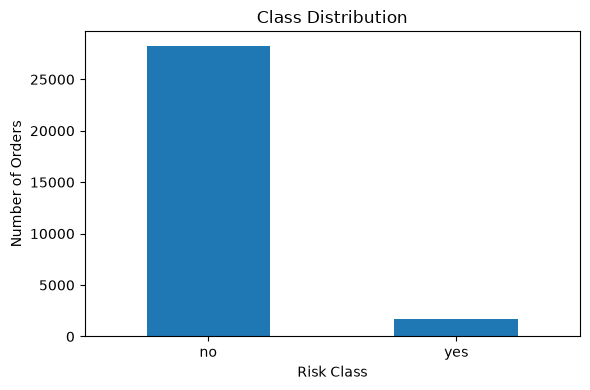

In [5]:
class_counts = df["CLASS"].value_counts()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Risk Class")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("outputs/class_distribution.png")
plt.show()

## 5. Missing Value Analysis

Missing values must be identified and handled before model training.

Numerical missing values will be replaced using the median, while categorical missing values will be replaced using the most frequent value.

In [6]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df) * 100).round(2)
})

display(missing_table)

,Missing Values,Percentage
ANUMMER_10,30000,100.00
ANUMMER_09,29993,99.98
ANUMMER_08,29966,99.89
ANUMMER_07,29905,99.68
ANUMMER_06,29794,99.31
ANUMMER_05,29459,98.20
ANUMMER_04,28668,95.56
ANUMMER_03,26802,89.34
ANUMMER_02,22147,73.82
Z_CARD_ART,18654,62.18


## 6. Feature Engineering and Feature Selection

Several raw attributes require transformation before modeling.

The following steps are applied:

- Remove `ORDER_ID` because it is an identifier.
- Extract numerical components from dates and time.
- Remove raw date/time columns after transformation.
- Remove high-cardinality product identifier fields (`ANUMMER_01` to `ANUMMER_10`).
- Encode categorical features.
- Standardize numerical features.

In [7]:
data = df.copy()

# -------------------------
# Birth Date
# -------------------------
birth_date = pd.to_datetime(
    data["B_BIRTHDATE"],
    errors="coerce"
)

data["BIRTH_YEAR"] = birth_date.dt.year
data["BIRTH_MONTH"] = birth_date.dt.month
data["BIRTH_DAY"] = birth_date.dt.day


# -------------------------
# Order Time
# -------------------------
order_time = pd.to_datetime(
    data["TIME_ORDER"],
    format="%H:%M",
    errors="coerce"
)

data["ORDER_HOUR"] = order_time.dt.hour
data["ORDER_MINUTE"] = order_time.dt.minute


# -------------------------
# Last Order Date
# -------------------------
last_order = pd.to_datetime(
    data["DATE_LORDER"],
    errors="coerce"
)

data["LAST_ORDER_YEAR"] = last_order.dt.year
data["LAST_ORDER_MONTH"] = last_order.dt.month
data["LAST_ORDER_DAY"] = last_order.dt.day


# -------------------------
# Card Expiration
# -------------------------
card_valid = data["Z_CARD_VALID"].str.split(
    ".",
    n=1,
    expand=True
)

data["CARD_VALID_MONTH"] = pd.to_numeric(
    card_valid[0],
    errors="coerce"
)

data["CARD_VALID_YEAR"] = pd.to_numeric(
    card_valid[1],
    errors="coerce"
)


# -------------------------
# Remove unnecessary fields
# -------------------------
product_columns = [
    f"ANUMMER_{i:02d}"
    for i in range(1, 11)
]

drop_columns = [
    "ORDER_ID",
    "B_BIRTHDATE",
    "TIME_ORDER",
    "DATE_LORDER",
    "Z_CARD_VALID"
] + product_columns

data = data.drop(columns=drop_columns)


print("Dataset after feature engineering:")
print(data.shape)

Dataset after feature engineering:
(30000, 39)


## 7. Target Variable

The target variable is converted into binary numerical values:

- Low Risk (`no`) = 0
- High Risk (`yes`) = 1

In [8]:
y = data["CLASS"].map({
    "no": 0,
    "yes": 1
}).astype(int)

X = data.drop(columns=["CLASS"])

print("Features:", X.shape)
print("Target:", y.shape)

print("\nEncoded Target:")
print(y.value_counts())

Features: (30000, 38)
Target: (30000,)

Encoded Target:
CLASS
0    28254
1     1746
Name: count, dtype: int64


## 8. Training, Validation, and Testing Sets

The data is divided into:

- 70% Training
- 15% Validation
- 15% Testing

Stratified sampling is used to preserve the class distribution.

The validation dataset is used to select the classification threshold without using the final testing dataset.

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (21000, 38)
Validation: (4500, 38)
Testing: (4500, 38)


## 9. Data Preprocessing

Numerical features are:

1. filled using the median
2. standardized

Categorical features are:

1. filled using the most frequent value
2. converted using one-hot encoding

In [10]:
numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()


numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])


categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_columns
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])


X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)


print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed validation shape:",
    X_val_processed.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)

Processed training shape: (21000, 68)
Processed validation shape: (4500, 68)
Processed testing shape: (4500, 68)


## 10. Cost-Sensitive Evaluation

The project uses unequal misclassification costs.

- Actual High Risk predicted as Low Risk: Cost = 50
- Actual Low Risk predicted as High Risk: Cost = 5

Therefore:

Total Cost = (False Negative × 50) + (False Positive × 5)

A validation set is used to select the threshold that minimizes this cost.

In [12]:
def calculate_cost(y_true, probabilities, threshold):
    
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (fn * 50) + (fp * 5)

    return total_cost


def find_best_threshold(
    y_true,
    probabilities
):
    
    thresholds = np.arange(
        0.05,
        0.96,
        0.01
    )

    costs = []

    for threshold in thresholds:
        cost = calculate_cost(
            y_true,
            probabilities,
            threshold
        )

        costs.append(cost)

    best_index = np.argmin(costs)

    return (
        thresholds[best_index],
        costs[best_index]
    )


def evaluate_model(
    name,
    split,
    y_true,
    probabilities,
    threshold
):
    
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Split": split,
        "Threshold": round(
            threshold,
            2
        ),
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "False Positive": fp,
        "False Negative": fn,
        "Cost": (fn * 50) + (fp * 5)
    }

## 11. Machine Learning Model 1: Logistic Regression

Logistic Regression is used as a baseline classification model.

Class weighting is applied because the dataset is imbalanced.

In [13]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED
)

logistic_model.fit(
    X_train_processed,
    y_train
)


logistic_val_prob = logistic_model.predict_proba(
    X_val_processed
)[:, 1]


logistic_threshold, logistic_val_cost = (
    find_best_threshold(
        y_val,
        logistic_val_prob
    )
)


print(
    "Best Logistic Regression Threshold:",
    round(logistic_threshold, 2)
)

print(
    "Validation Cost:",
    logistic_val_cost
)

Best Logistic Regression Threshold: 0.68
Validation Cost: 9705


## 12. Machine Learning Model 2: Random Forest

Random Forest is used as a nonlinear machine learning model.

Class weighting is applied to reduce the effect of class imbalance.

In [14]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train
)


rf_val_prob = random_forest_model.predict_proba(
    X_val_processed
)[:, 1]


rf_threshold, rf_val_cost = (
    find_best_threshold(
        y_val,
        rf_val_prob
    )
)


print(
    "Best Random Forest Threshold:",
    round(rf_threshold, 2)
)

print(
    "Validation Cost:",
    rf_val_cost
)

Best Random Forest Threshold: 0.08
Validation Cost: 9775


## 13. Deep Learning Model: PyTorch Neural Network

A feed-forward neural network is implemented using PyTorch.

Architecture:

Input Layer → 64 Neurons → 32 Neurons → Output Layer

ReLU activation and dropout are used in the hidden layers.

The output represents the probability that an order belongs to the High Risk class.

In [15]:
X_train_tensor = torch.tensor(
    X_train_processed,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)


X_val_tensor = torch.tensor(
    X_val_processed,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed,
    dtype=torch.float32
)


train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)


train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)


print(
    "PyTorch Input Features:",
    X_train_tensor.shape[1]
)

PyTorch Input Features: 68


In [16]:
class RiskNeuralNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_size,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                64,
                32
            ),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                32,
                1
            )
        )

    def forward(self, x):
        return self.network(x)


neural_model = RiskNeuralNetwork(
    X_train_tensor.shape[1]
)

print(neural_model)

RiskNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=68, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 14. Neural Network Training

Binary Cross Entropy with logits is used as the loss function.

A positive-class weight is applied because High Risk orders are much less common than Low Risk orders.

In [17]:
negative_count = (
    y_train == 0
).sum()

positive_count = (
    y_train == 1
).sum()


positive_weight = torch.tensor(
    [
        negative_count /
        positive_count
    ],
    dtype=torch.float32
)


loss_function = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight
)


optimizer = torch.optim.Adam(
    neural_model.parameters(),
    lr=0.001
)


EPOCHS = 20

training_losses = []


for epoch in range(EPOCHS):

    neural_model.train()

    total_loss = 0

    for features, labels in train_loader:

        optimizer.zero_grad()

        outputs = neural_model(features)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item() *
            len(features)
        )


    average_loss = (
        total_loss /
        len(train_loader.dataset)
    )

    training_losses.append(
        average_loss
    )


    if (
        epoch == 0
        or (epoch + 1) % 5 == 0
    ):
        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} "
            f"- Loss: {average_loss:.4f}"
        )

Epoch 01/20 - Loss: 1.2758
Epoch 05/20 - Loss: 1.1614
Epoch 10/20 - Loss: 1.1207
Epoch 15/20 - Loss: 1.0895
Epoch 20/20 - Loss: 1.0614


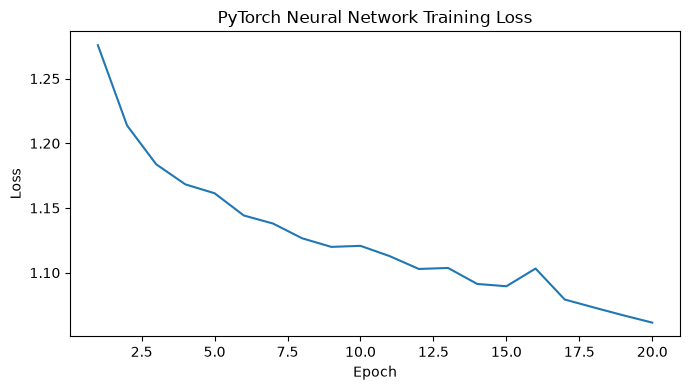

In [18]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, EPOCHS + 1),
    training_losses
)

plt.title(
    "PyTorch Neural Network Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.tight_layout()

plt.savefig(
    "outputs/neural_network_training_loss.png"
)

plt.show()

In [19]:
neural_model.eval()

with torch.no_grad():

    neural_val_prob = torch.sigmoid(
        neural_model(
            X_val_tensor
        )
    ).numpy().flatten()


nn_threshold, nn_val_cost = (
    find_best_threshold(
        y_val,
        neural_val_prob
    )
)


print(
    "Best Neural Network Threshold:",
    round(nn_threshold, 2)
)

print(
    "Validation Cost:",
    nn_val_cost
)

Best Neural Network Threshold: 0.74
Validation Cost: 9925


## 15. Model Evaluation

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- False Positives
- False Negatives
- Misclassification Cost

Both training and testing performance are reported.

In [20]:
# Logistic Regression

logistic_train_prob = (
    logistic_model.predict_proba(
        X_train_processed
    )[:, 1]
)

logistic_test_prob = (
    logistic_model.predict_proba(
        X_test_processed
    )[:, 1]
)


# Random Forest

rf_train_prob = (
    random_forest_model.predict_proba(
        X_train_processed
    )[:, 1]
)

rf_test_prob = (
    random_forest_model.predict_proba(
        X_test_processed
    )[:, 1]
)


# PyTorch

neural_model.eval()

with torch.no_grad():

    neural_train_prob = torch.sigmoid(
        neural_model(
            X_train_tensor
        )
    ).numpy().flatten()

    neural_test_prob = torch.sigmoid(
        neural_model(
            X_test_tensor
        )
    ).numpy().flatten()

In [21]:
results = []


# Logistic Regression
results.append(
    evaluate_model(
        "Logistic Regression",
        "Train",
        y_train,
        logistic_train_prob,
        logistic_threshold
    )
)

results.append(
    evaluate_model(
        "Logistic Regression",
        "Test",
        y_test,
        logistic_test_prob,
        logistic_threshold
    )
)


# Random Forest
results.append(
    evaluate_model(
        "Random Forest",
        "Train",
        y_train,
        rf_train_prob,
        rf_threshold
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        "Test",
        y_test,
        rf_test_prob,
        rf_threshold
    )
)


# Neural Network
results.append(
    evaluate_model(
        "PyTorch Neural Network",
        "Train",
        y_train,
        neural_train_prob,
        nn_threshold
    )
)

results.append(
    evaluate_model(
        "PyTorch Neural Network",
        "Test",
        y_test,
        neural_test_prob,
        nn_threshold
    )
)


results_df = pd.DataFrame(
    results
)


display(
    results_df.round(4)
)


results_df.to_csv(
    "outputs/model_results.csv",
    index=False
)

,Model,Split,Threshold,Accuracy,Precision,Recall,F1 Score,False Positive,False Negative,Cost
0,Logistic Regression,Train,0.68,0.8796,0.2009,0.3592,0.2577,1746,783,47880
1,Logistic Regression,Test,0.68,0.8787,0.2029,0.3702,0.2622,381,165,10155
2,Random Forest,Train,0.08,0.9808,0.7520,1.0000,0.8584,403,0,2015
3,Random Forest,Test,0.08,0.7880,0.1498,0.5649,0.2368,840,114,9900
4,PyTorch Neural Network,Train,0.74,0.8956,0.2475,0.3895,0.3027,1447,746,44535
5,PyTorch Neural Network,Test,0.74,0.8867,0.2075,0.3359,0.2566,336,174,10380


## 16. Confusion Matrices

Confusion matrices are used to show correct and incorrect classifications for each model.

False negatives are particularly important because failing to detect a High Risk order has the highest cost.

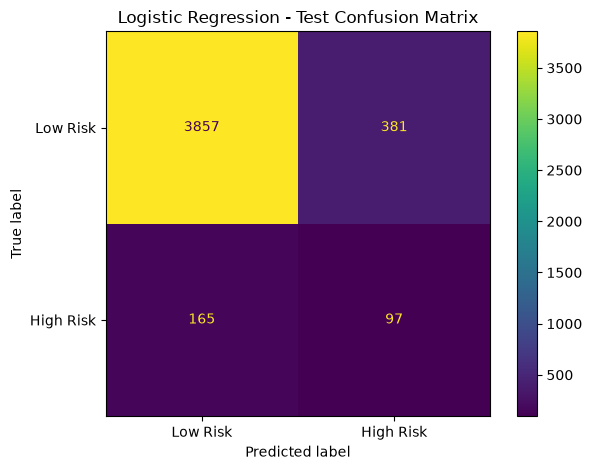

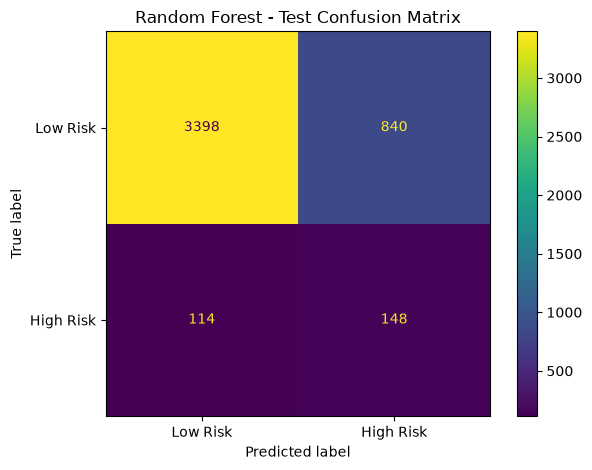

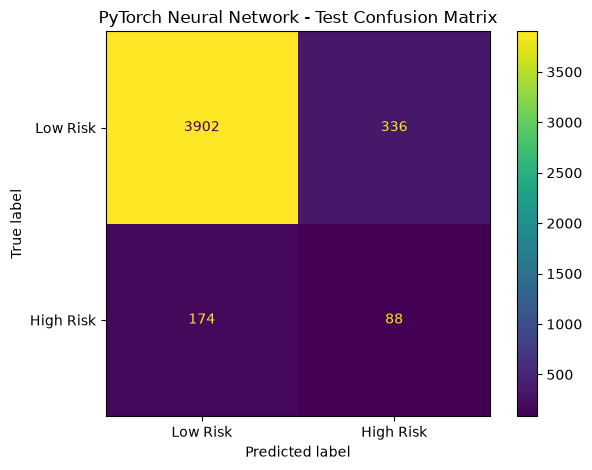

In [22]:
test_models = {
    
    "Logistic Regression": (
        logistic_test_prob,
        logistic_threshold
    ),
    
    "Random Forest": (
        rf_test_prob,
        rf_threshold
    ),
    
    "PyTorch Neural Network": (
        neural_test_prob,
        nn_threshold
    )
}


for model_name, (
    probabilities,
    threshold
) in test_models.items():

    predictions = (
        probabilities >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=[
            "Low Risk",
            "High Risk"
        ]
    )

    plt.title(
        f"{model_name} - Test Confusion Matrix"
    )

    plt.tight_layout()

    file_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    plt.savefig(
        f"outputs/{file_name}_confusion_matrix.png"
    )

    plt.show()

## 17. Model Comparison

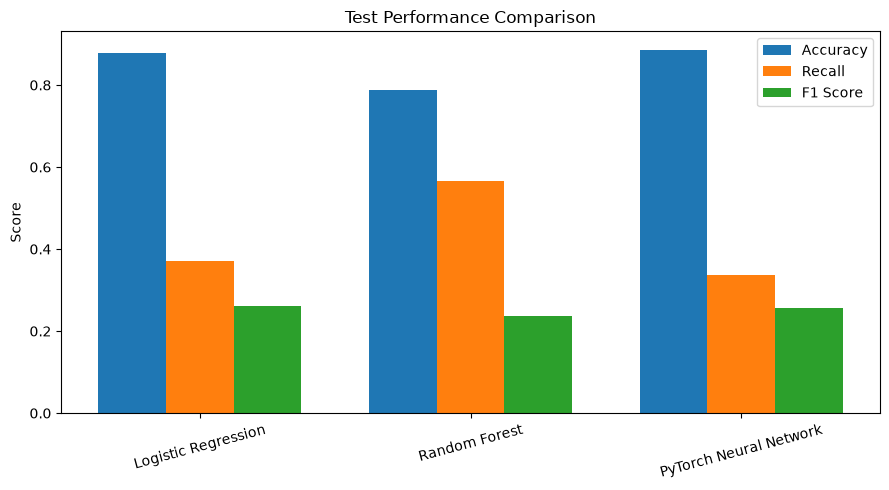

In [23]:
test_results = results_df[
    results_df["Split"] == "Test"
].copy()


x = np.arange(
    len(test_results)
)

width = 0.25


plt.figure(figsize=(9, 5))


plt.bar(
    x - width,
    test_results["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x,
    test_results["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    test_results["F1 Score"],
    width,
    label="F1 Score"
)


plt.xticks(
    x,
    test_results["Model"],
    rotation=15
)

plt.ylabel("Score")

plt.title(
    "Test Performance Comparison"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "outputs/model_performance_comparison.png"
)

plt.show()

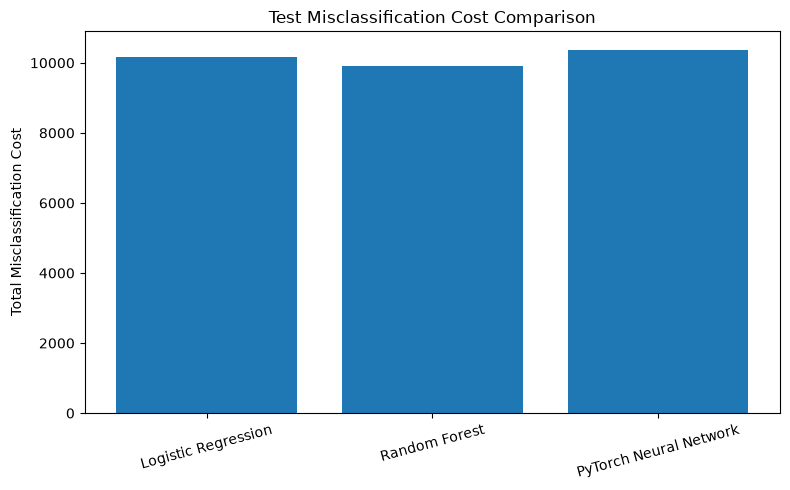

In [24]:
plt.figure(figsize=(8, 5))

plt.bar(
    test_results["Model"],
    test_results["Cost"]
)

plt.title(
    "Test Misclassification Cost Comparison"
)

plt.ylabel(
    "Total Misclassification Cost"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    "outputs/cost_comparison.png"
)

plt.show()

## 18. Final Model Selection

Because the cost of missing a High Risk order is much higher than incorrectly flagging a Low Risk order, model selection should consider misclassification cost in addition to standard classification metrics.

The final model is selected based primarily on validation misclassification cost and then evaluated on the independent testing dataset.

In [25]:
validation_summary = pd.DataFrame({
    
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "PyTorch Neural Network"
    ],

    "Validation Cost": [
        logistic_val_cost,
        rf_val_cost,
        nn_val_cost
    ],

    "Threshold": [
        logistic_threshold,
        rf_threshold,
        nn_threshold
    ]
})


display(validation_summary)


best_index = (
    validation_summary[
        "Validation Cost"
    ].idxmin()
)


best_model = validation_summary.loc[
    best_index,
    "Model"
]


print(
    "\nSelected Final Model:",
    best_model
)

,Model,Validation Cost,Threshold
0,Logistic Regression,9705,0.68
1,Random Forest,9775,0.08
2,PyTorch Neural Network,9925,0.74



Selected Final Model: Logistic Regression


## 19. Conclusion

This project developed and compared three classification approaches for online purchase order risk prediction:

1. Logistic Regression
2. Random Forest
3. PyTorch Neural Network

The dataset required preprocessing because it contained missing values, categorical variables, date/time information, and class imbalance.

The models were evaluated using Accuracy, Precision, Recall, F1 Score, confusion matrices, and the provided misclassification cost matrix.

Because failing to identify a High Risk order has a substantially higher cost, the final model should not be selected using accuracy alone. Misclassification cost and High Risk recall are especially important for this application.